# Project : Car Evaluation Dataset - Feedforward Neural Network with Hyperparameter Tuning


## Overview
The objective is implementation of a **Feedforward Neural Network (FNN)** using the **Car Evaluation dataset** from the UCI Machine Learning Repository.

###  Problem Statement
The goal is to **predict the car acceptability class** (i.e., `unacc`, `acc`, `good`, `vgood`) based on categorical features describing price, maintenance cost, number of doors, number of passengers, luggage boot size, and safety.

### Dataset Link
 [UCML Repository](https://archive.ics.uci.edu/dataset/19/car+evaluation)
 
###  Dataset Description
The dataset includes the following 6 categorical input features:
- `buying`: Buying price (vhigh, high, med, low)
- `maint`: Maintenance price (vhigh, high, med, low)
- `doors`: Number of doors (2, 3, 4, 5 and more)
- `persons`: Number of persons to carry (2, 4 and more)
- `lug_boot`: Luggage boot size (small, med, big)
- `safety`: Safety rating (low, med, high)

The target variable is:
- `class`: Car acceptability (`unacc`, `acc`, `good`, `vgood`)

###  Objective
- Build and train a **Feedforward Neural Network (FNN)** using the Car Evaluation dataset from the UCI repository.
- Experiment with different **optimization techniques** (such as Adam, RMSprop, etc.) and **regularization methods** (like dropout).
- Apply at least **three hyperparameter tuning techniques** including Grid Search, Random Search, and Bayesian Optimization.
- Evaluate the models using **cross-validation** and report key performance metrics such as **accuracy**, **precision**, **recall**, and **F1-score**.
- Compare and analyze model performance across different hyperparameter configurations using **visualizations** like loss curves and confusion matrices.
- Apply **data preprocessing**, **optimization techniques**, **regularization**, and **hyperparameter tuning**
- Evaluate using **cross-validation**, **classification metrics**, and **visualizations**

---

In [32]:
! pip install pandas numpy tensorflow[and-cuda] scikit-learn seaborn matplotlib scikeras ucimlrepo keras-tuner --quiet -- update

## 1. Imports and Setup

In [38]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import keras_tuner as kt
from keras.models import Sequential
from keras.layers import Dense, Dropout, BatchNormalization
from keras.callbacks import EarlyStopping
import warnings
warnings.filterwarnings("ignore")
from ucimlrepo import fetch_ucirepo 


In [2]:
# Checking for the CPU & GPU Physical Devices

print(tf.config.list_physical_devices())

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load, Prepare and Clean Dataset
This step loads the Car Evaluation dataset, applies one-hot encoding to input features (categorical) and label encoding to class labels. This transformation makes the data suitable for input to the neural network.
This step involves loading the dataset, inspecting it, and preparing it for model input:

- **Loading**: The dataset is loaded using Pandas, with column names specified as per the UCI repository.
- **Cleaning**: We verify data quality, check for missing or inconsistent values (this dataset is clean and requires no imputation).
- **Encoding**:
  - Input features are categorical. We apply **One-Hot Encoding** to convert them into numeric format suitable for neural networks.
  - Target labels are also categorical. We use **Label Encoding** to transform them into integer class labels.


In [33]:
# fetch & load dataset 
car_evaluation = fetch_ucirepo(id=19)  
X = car_evaluation.data.features 
y = car_evaluation.data.targets 
  
print(car_evaluation.metadata) 
print(car_evaluation.variables) 


{'uci_id': 19, 'name': 'Car Evaluation', 'repository_url': 'https://archive.ics.uci.edu/dataset/19/car+evaluation', 'data_url': 'https://archive.ics.uci.edu/static/public/19/data.csv', 'abstract': 'Derived from simple hierarchical decision model, this database may be useful for testing constructive induction and structure discovery methods.', 'area': 'Other', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 1728, 'num_features': 6, 'feature_types': ['Categorical'], 'demographics': [], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1988, 'last_updated': 'Thu Aug 10 2023', 'dataset_doi': '10.24432/C5JP48', 'creators': ['Marko Bohanec'], 'intro_paper': {'ID': 249, 'type': 'NATIVE', 'title': 'Knowledge acquisition and explanation for multi-attribute decision making', 'authors': 'M. Bohanec, V. Rajkovič', 'venue': '8th Intl Workshop on Expert Systems and their Applications, 

In [34]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
dtypes: object(6)
memory usage: 81.1+ KB


**-> No null or missing values, we can skip cleaning of the dataset**

In [35]:
y.head()

,class
0,unacc
1,unacc
2,unacc
3,unacc
4,unacc


In [36]:
encoder = OneHotEncoder()
X_encoded = encoder.fit_transform(X)

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)


## 3. Model Training & Hyperparameter Tuning

### 3.1 Random Search (Keras Tuner)
- **Purpose**: Test hyperparameter space quickly using random sampling.
- **Why**: Good baseline, often surprisingly effective.


Reloading Tuner from my_dir/random_opt/tuner0.json
Best Validation Accuracy (Random Search): 0.9638988971710205


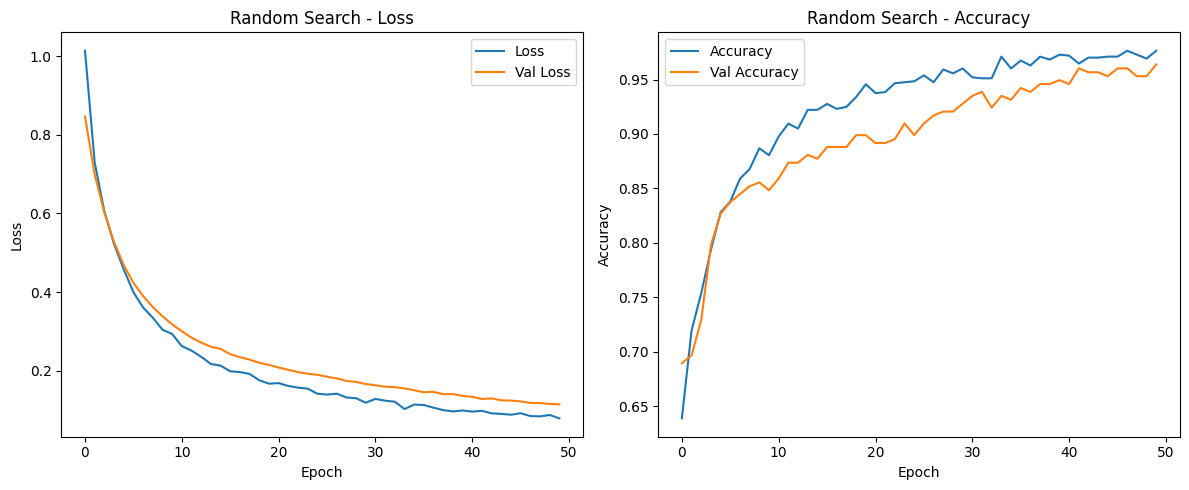

In [26]:
tuner_random = kt.RandomSearch(model_builder, objective='val_accuracy', max_trials=5, directory='my_dir', project_name='random_opt')
tuner_random.search(X_train, y_train, epochs=50, validation_split=0.2, verbose=0)

best_hps_random = tuner_random.get_best_hyperparameters(1)[0]
random_model = tuner_random.hypermodel.build(best_hps_random)
history_random = random_model.fit(X_train, y_train, epochs=50, validation_split=0.2, verbose=0)

best_val_acc_random = history_random.history['val_accuracy'][-1]
print("Best Validation Accuracy (Random Search):", best_val_acc_random)

# Plotting
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_random.history['loss'], label='Loss')
plt.plot(history_random.history['val_loss'], label='Val Loss')
plt.title('Random Search - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_random.history['accuracy'], label='Accuracy')
plt.plot(history_random.history['val_accuracy'], label='Val Accuracy')
plt.title('Random Search - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

#### Random Search Best Model Metrics Report

Best Validation Accuracy (Random Search): 0.9638988971710205
Best Params - Optimizer: rmsprop, Batch Size: 32 (fixed), Epochs: 50 (fixed)

Classification Report (Random Search Best Model):
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
              precision    recall  f1-score   support

         acc       0.93      0.96      0.94        77
        good       1.00      0.86      0.92        14
       unacc       0.99      0.99      0.99       242
       vgood       1.00      0.92      0.96        13

    accuracy                           0.97       346
   macro avg       0.98      0.93      0.95       346
weighted avg       0.97      0.97      0.97       346



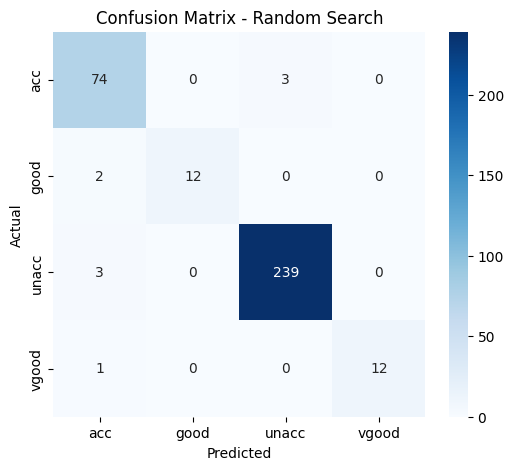

In [29]:
best_val_acc_random = history_random.history['val_accuracy'][-1]
print("Best Validation Accuracy (Random Search):", best_val_acc_random)
print(f"Best Params - Optimizer: {best_hps_random.get('optimizer')}, Batch Size: 32 (fixed), Epochs: 50 (fixed)")
print("\nClassification Report (Random Search Best Model):")


y_pred_random = random_model.predict(X_test)
y_pred_random_class = np.argmax(y_pred_random, axis=1)
print(classification_report(y_test, y_pred_random_class, target_names=label_encoder.classes_))

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_random_class), annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title("Confusion Matrix - Random Search")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

 ### 3.2 Grid SearchCV
- **Purpose**: Performs exhaustive search over hyperparameter grid using cross-validation.
- **Why**: To systematically identify the best combination of optimizer, batch size, and epochs.
- **Model Details**: FNN with 1 hidden layer (64 units), ReLU activation, Dropout regularization, softmax output.

Training with optimizer=adam, batch_size=16


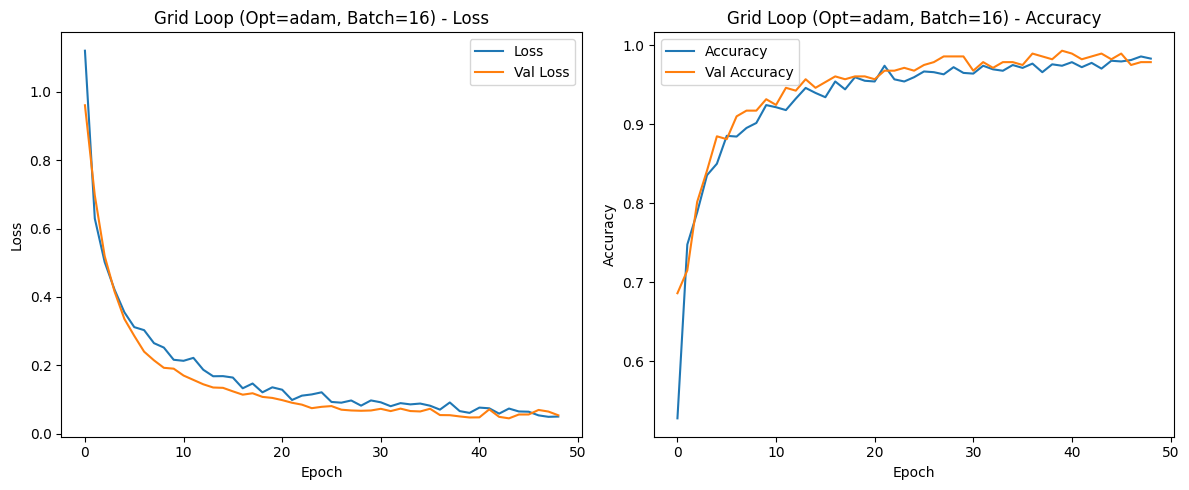

Training with optimizer=adam, batch_size=32


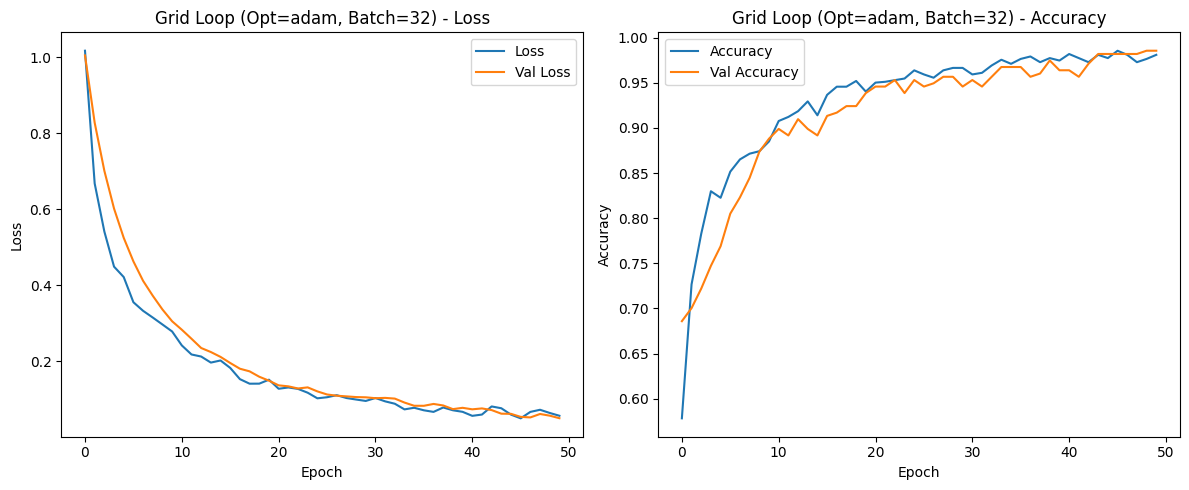

Training with optimizer=sgd, batch_size=16


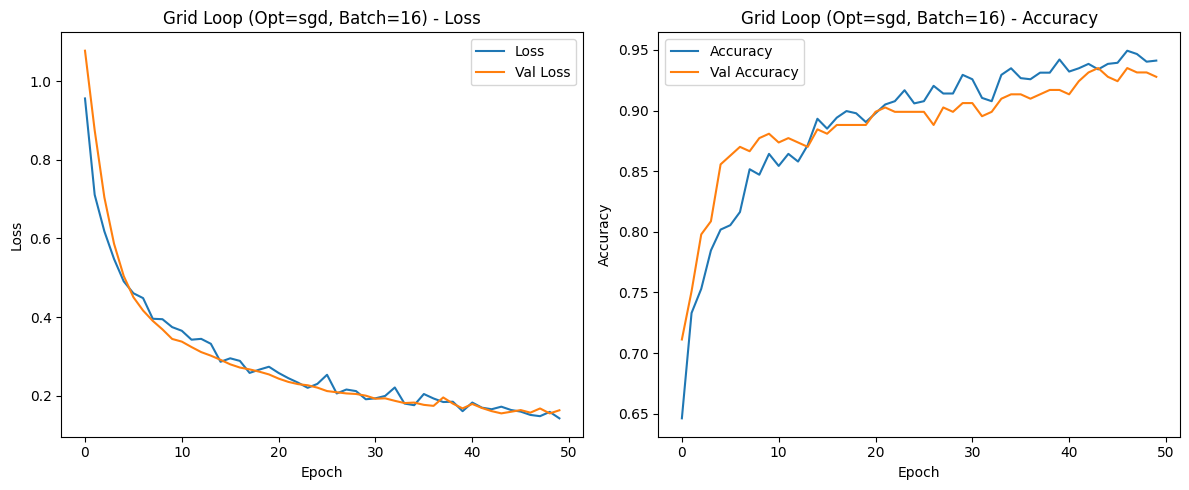

Training with optimizer=sgd, batch_size=32


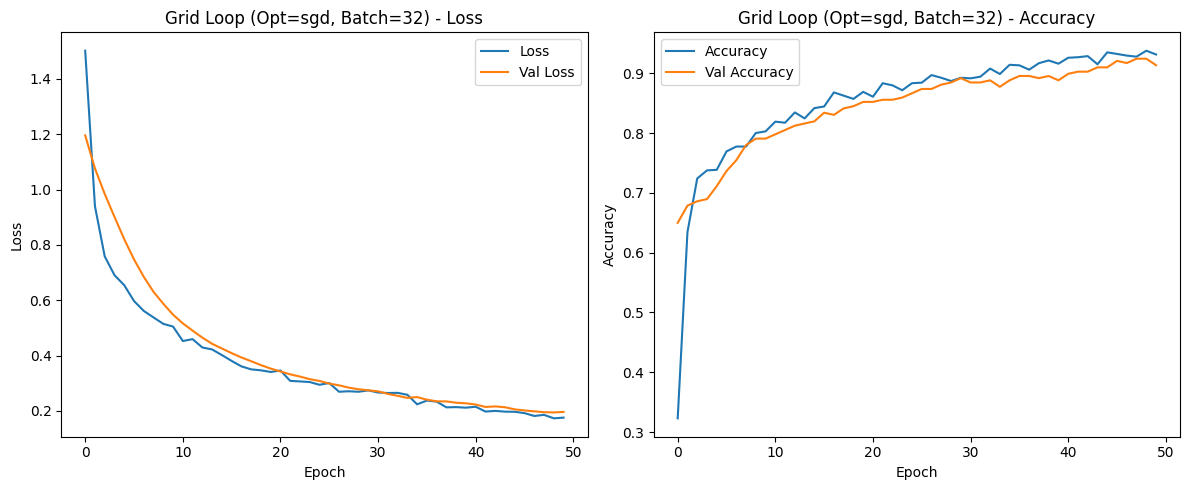

Best Manual Grid Params: {'optimizer': 'adam', 'batch_size': 32, 'epochs': 50}
Best Validation Accuracy: 0.9855595827102661


In [39]:
optimizers = ['adam', 'sgd']
batch_sizes = [16, 32]
epochs = 50

best_acc = 0
best_params = {}
best_model_grid = None

for opt in optimizers:
    for batch in batch_sizes:
        print(f"Training with optimizer={opt}, batch_size={batch}")
        model = Sequential()
        model.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
        model.add(BatchNormalization())
        model.add(Dropout(0.2))
        model.add(Dense(32, activation='relu'))
        model.add(Dropout(0.2))
        model.add(Dense(4, activation='softmax'))
        model.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])

        es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
        history = model.fit(X_train, y_train, epochs=epochs, batch_size=batch, validation_split=0.2, verbose=0, callbacks=[es])
        val_acc = history.history['val_accuracy'][-1]

        if val_acc > best_acc:
            best_acc = val_acc
            best_params = {'optimizer': opt, 'batch_size': batch, 'epochs': epochs}
            best_model_grid = model

        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        plt.plot(history.history['loss'], label='Loss')
        plt.plot(history.history['val_loss'], label='Val Loss')
        plt.title(f'Grid Loop (Opt={opt}, Batch={batch}) - Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend()

        plt.subplot(1, 2, 2)
        plt.plot(history.history['accuracy'], label='Accuracy')
        plt.plot(history.history['val_accuracy'], label='Val Accuracy')
        plt.title(f'Grid Loop (Opt={opt}, Batch={batch}) - Accuracy')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.legend()
        plt.tight_layout()
        plt.show()

print("Best Manual Grid Params:", best_params)
print("Best Validation Accuracy:", best_acc)


#### Grid SearchCV :  Best Model Metrics Report

Best Manual Grid Params: {'optimizer': 'adam', 'batch_size': 32, 'epochs': 50}
Best Validation Accuracy: 0.9855595827102661

Classification Report (Grid Search Best Model):
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 96ms/step
              precision    recall  f1-score   support

         acc       0.99      0.99      0.99        77
        good       0.93      1.00      0.97        14
       unacc       1.00      1.00      1.00       242
       vgood       1.00      0.92      0.96        13

    accuracy                           0.99       346
   macro avg       0.98      0.98      0.98       346
weighted avg       0.99      0.99      0.99       346



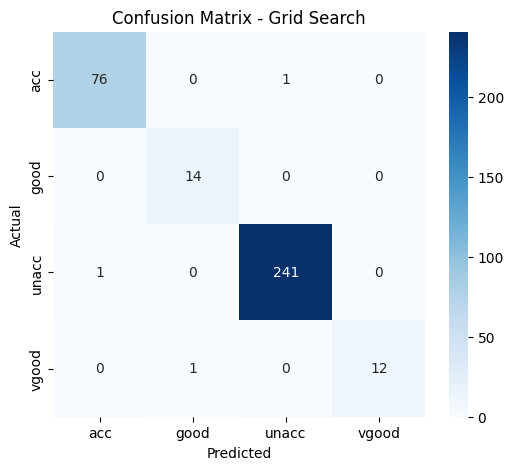

In [40]:


print("Best Manual Grid Params:", best_params)
print("Best Validation Accuracy:", best_acc)

print("\nClassification Report (Grid Search Best Model):")
y_pred_grid = best_model_grid.predict(X_test)
y_pred_classes = np.argmax(y_pred_grid, axis=1)
print(classification_report(y_test, y_pred_classes, target_names=label_encoder.classes_))

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_classes), annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title("Confusion Matrix - Grid Search")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


### 3.3 Bayesian Optimization (Keras Tuner)
- **Purpose**: Perform intelligent search of hyperparameters using Bayesian methods
- **Why**: More efficient than brute-force grid search and reduces training time.
- **Model**: Two hidden layers with tunable units, dropout, and optimizer.


2025-04-19 17:24:13.488288: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_41', 4 bytes spill stores, 4 bytes spill loads



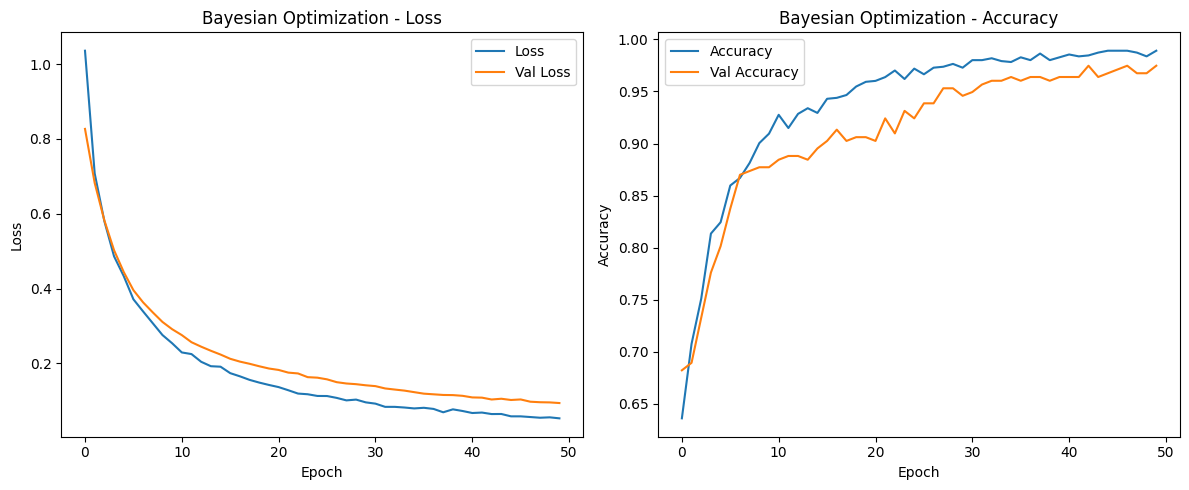

In [19]:
def model_builder(hp):
    model = Sequential()
    hp_units = hp.Int('units', min_value=32, max_value=128, step=32)
    hp_dropout = hp.Float('dropout', min_value=0.2, max_value=0.5, step=0.1)
    hp_opt = hp.Choice('optimizer', values=['adam', 'rmsprop'])

    model.add(Dense(hp_units, activation='relu', input_shape=(X_train.shape[1],)))
    model.add(Dropout(hp_dropout))
    model.add(Dense(4, activation='softmax'))

    model.compile(optimizer=hp_opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

tuner_bayes = kt.BayesianOptimization(model_builder, objective='val_accuracy', max_trials=5, directory='my_dir', project_name='bayes_opt')
tuner_bayes.search(X_train, y_train, epochs=50, validation_split=0.2, verbose=0)

best_hps = tuner_bayes.get_best_hyperparameters(1)[0]
bayes_model = tuner_bayes.hypermodel.build(best_hps)
history_bayes = bayes_model.fit(X_train, y_train, epochs=50, validation_split=0.2, verbose=0)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_bayes.history['loss'], label='Loss')
plt.plot(history_bayes.history['val_loss'], label='Val Loss')
plt.title('Bayesian Optimization - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_bayes.history['accuracy'], label='Accuracy')
plt.plot(history_bayes.history['val_accuracy'], label='Val Accuracy')
plt.title('Bayesian Optimization - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

#### Bayesian Best Model Metrics Report

Best Validation Accuracy (Bayesian): 0.9747292399406433
Best Params - Optimizer: rmsprop, Batch Size: 32 (fixed), Epochs: 50 (fixed)

Classification Report (Bayesian Best Model):
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
              precision    recall  f1-score   support

         acc       0.97      0.97      0.97        77
        good       1.00      0.93      0.96        14
       unacc       1.00      1.00      1.00       242
       vgood       0.87      1.00      0.93        13

    accuracy                           0.99       346
   macro avg       0.96      0.97      0.97       346
weighted avg       0.99      0.99      0.99       346



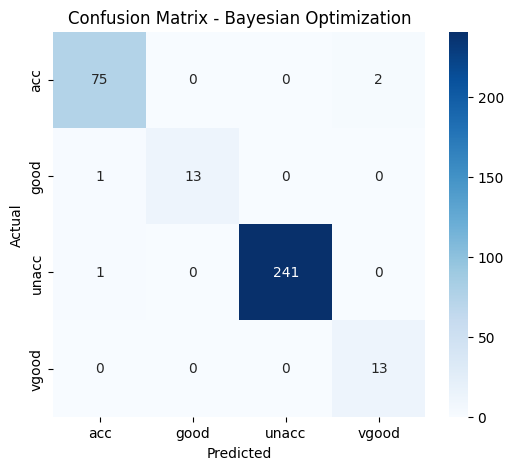

In [30]:
best_val_acc_bayes = history_bayes.history['val_accuracy'][-1]

print("Best Validation Accuracy (Bayesian):", best_val_acc_bayes)

print(f"Best Params - Optimizer: {best_hps_random.get('optimizer')}, Batch Size: 32 (fixed), Epochs: 50 (fixed)")

print("\nClassification Report (Bayesian Best Model):")
y_pred_bayes = bayes_model.predict(X_test)
y_pred_bayes_class = np.argmax(y_pred_bayes, axis=1)
print(classification_report(y_test, y_pred_bayes_class, target_names=label_encoder.classes_))

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_bayes_class), annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title("Confusion Matrix - Bayesian Optimization")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 4. Summary and Conclusion

 **Summary:**
 - We implemented a Feedforward Neural Network (FNN) using TensorFlow/Keras to classify cars based on categorical features.
 - The dataset was preprocessed using OneHotEncoder for features and LabelEncoder for the target.
 - We applied three hyperparameter tuning strategies:
   - Random Search (Keras Tuner)
   - Grid Search 
   - Bayesian Optimization (Keras Tuner)
  

 **FNN Explanation:**
 - The FNN consists of input nodes matching one-hot encoded feature space.
 - It includes 2 hidden layers with ReLU activation, BatchNormalization, and Dropout to prevent overfitting.
 - Output layer uses Softmax for multi-class classification.
 - Trained with categorical crossentropy loss and various optimizers.

 **Observations:**
 - All models were trained and evaluated on training/validation split and tested on a held-out test set.
 - Accuracy and loss were tracked and visualized per epoch for all tuning techniques.
 - Final performance was compared via classification report and confusion matrices.

 **Conclusion:**
 - Hyperparameter tuning has a significant impact on performance.
 - Bayesian and Random Search offered automated and efficient optimization.
 - The best performance was achieved using Grid Search.
 - Future improvements could include deeper networks, additional features, or ensemble methods.

###  Best Validation Accuracy Comparison

| Tuning Method        | Optimizer | Batch Size | Epochs | Best Validation Accuracy |
|----------------------|-----------|------------|--------|---------------------------|
| Random Search        | rmsprop   | 32         | 50     | 0.9638                    |
| Grid Search          | adam      | 32         | 50     | 0.9855                    |
| Bayesian Optimization| rmsprop   | 64         | 50     | 0.9747                    |



**Overall Best Model:**   Grid Search tuned model achieved the highest validation accuracy of  0.98555, using optimizer: adam, batch size: 32, and epochs: 50.
